In [ ]:
!pip install -q torch torchvision transformers datasets matplotlib numpy

In [2]:
import math
import time
import warnings

import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import transformers
from datasets import load_dataset
from torchvision.ops import roi_align
from transformers import AutoModel, AutoProcessor

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
CIFAR_NAME = "uoft-cs/cifar10"
CLIP_NAME = "openai/clip-vit-base-patch32"
SIGLIP_NAME = "google/siglip2-base-patch16-224"
PAIRS_NAME = "jxie/flickr8k"
SEED = 0
torch.manual_seed(SEED)
print(f"DEVICE = {DEVICE}")

DEVICE = mps


# Contrastive Learning

Contrastive learning trains an encoder without class labels by turning representation learning
into a classification problem the data labels for free: *which of these $N$ candidates belongs
with this anchor?* The positive is another view of the same image (SimCLR, MoCo) or the caption
that came with it (CLIP, SigLIP); every other item in the batch is a negative. The family covers
most of modern vision pretraining:

| Method | Positive pair | Negatives | Loss |
|---|---|---|---|
| SimCLR (2020) | two augmentations of one image | the other $2N-2$ views in the batch | NT-Xent (softmax) |
| MoCo v2/v3 (2020–21) | two augmentations | a queue / momentum-encoder keys | InfoNCE |
| CLIP (2021) | image and its caption | all other captions / images in the batch | symmetric InfoNCE |
| SigLIP / SigLIP 2 (2023–25) | image and its caption | every non-matching pair, independently | pairwise sigmoid |
| DINO, BYOL, iBOT | two views | none (self-distillation) | cross-entropy to a teacher |

The self-supervised image side is trained from scratch with SimCLR; the image–text side is
built as loss functions and checked against two released models, CLIP ViT-B/32 and
SigLIP 2 ViT-B/16, on real captioned photos.

---

# 1) The Math

**InfoNCE.** For an anchor $q$, one positive $k^+$ and negatives $k_1^-, \dots$, all unit
vectors,

$$\mathcal{L}_{\text{NCE}} = -\log \frac{e^{q^\top k^+ / \tau}}{e^{q^\top k^+/\tau} + \sum_j e^{q^\top k_j^-/\tau}} .$$

It is a lower bound on mutual information, $I(q; k) \ge \log N - \mathcal{L}_{\text{NCE}}$, so more
negatives make the bound tighter; that is why SimCLR and CLIP want huge batches. The temperature
$\tau$ decides how much the hardest negatives dominate the gradient.

**NT-Xent (SimCLR).** A batch of $N$ images gives $2N$ views $z_1..z_{2N}$. View $i$'s
positive is its partner $p(i)$; the other $2N-2$ views are negatives:

$$\mathcal{L} = \frac{1}{2N}\sum_{i=1}^{2N} -\log \frac{\exp(z_i^\top z_{p(i)}/\tau)}{\sum_{k \ne i} \exp(z_i^\top z_k/\tau)} .$$

**CLIP.** With image embeddings $u_i$, text embeddings $v_j$ and a learned scale $t = 1/\tau$,
logits $s_{ij} = t\, u_i^\top v_j$ and the loss is the average of row-wise and column-wise
cross-entropy with targets on the diagonal:

$$\mathcal{L}_{\text{CLIP}} = \tfrac{1}{2}\big[\text{CE}(S, \text{diag}) + \text{CE}(S^\top, \text{diag})\big].$$

**SigLIP.** Every pair is its own binary problem with label $y_{ij} = +1$ on the diagonal and
$-1$ elsewhere, a learned scale $t$ and bias $b$:

$$\mathcal{L}_{\text{SigLIP}} = -\frac{1}{N} \sum_{i=1}^{N}\sum_{j=1}^{N} \log \sigma\big(y_{ij}\,(t\, u_i^\top v_j + b)\big).$$

No normalisation over the batch, so the loss of a pair does not depend on which other pairs
share its batch, the full $N \times N$ softmax never has to be gathered across devices, and the
bias (initialised at $b = -10$) absorbs the $N^2 - N$ negatives so the model starts at the right
prior.

In [3]:
def nt_xent(z1: torch.Tensor, z2: torch.Tensor, tau: float) -> torch.Tensor:
    """SimCLR loss. z1, z2 (batch_num, D) unit vectors of two views."""
    z = torch.cat([z1, z2])
    n = len(z1)
    sim = z @ z.T / tau
    sim.fill_diagonal_(-float("inf"))
    # view i's partner sits n rows away
    targets = torch.cat([torch.arange(n, 2 * n), torch.arange(n)]).to(z.device)
    return F.cross_entropy(sim, targets)


def clip_loss(u: torch.Tensor, v: torch.Tensor, scale: torch.Tensor) -> torch.Tensor:
    """Symmetric InfoNCE. u, v (batch_num, D) unit image / text embeddings."""
    logits = scale * u @ v.T
    targets = torch.arange(len(u), device=u.device)
    return (F.cross_entropy(logits, targets) + F.cross_entropy(logits.T, targets)) / 2


def siglip_loss(
    u: torch.Tensor, v: torch.Tensor, scale: torch.Tensor, bias: torch.Tensor
) -> torch.Tensor:
    """Pairwise sigmoid loss: sum over texts, mean over images."""
    logits = scale * u @ v.T + bias
    labels = 2 * torch.eye(len(u), device=u.device) - 1
    return -F.logsigmoid(labels * logits).sum(dim=1).mean()


z1 = F.normalize(torch.randn(4, 8), dim=1)
z2 = F.normalize(z1 + 0.1 * torch.randn(4, 8), dim=1)
# NT-Xent by an explicit loop over the 2N anchors
z = torch.cat([z1, z2])
terms = []
for i in range(8):
    others = [k for k in range(8) if k != i]
    logits = torch.stack([z[i] @ z[k] / 0.5 for k in others])
    terms.append(-logits[others.index((i + 4) % 8)] + torch.logsumexp(logits, 0))
print(
    f"NT-Xent: vectorised {nt_xent(z1, z2, 0.5):.5f} | loop "
    f"{torch.stack(terms).mean():.5f}"
)
u_rand, v_rand = F.normalize(torch.randn(2, 64, 8), dim=-1)
chance = clip_loss(u_rand, v_rand, torch.tensor(1.0))
print(
    f"random unit vectors, N=64: CLIP loss {chance:.3f} vs log N = {math.log(64):.3f}"
)

NT-Xent: vectorised 0.95209 | loop 0.95209
random unit vectors, N=64: CLIP loss 4.301 vs log N = 4.159


# 2) SimCLR from Scratch on CIFAR-10

**Augmentations are the supervision.** The views must share the object and differ in
everything the representation should ignore. SimCLR found two ingredients essential: random
resized crops (the model must match a part to a whole, or two parts) and strong colour jitter
(otherwise the colour histogram alone identifies the pair).

The augmentations run batched on the GPU: one random box per image is cut and resized with
`roi_align`, then flips, brightness/contrast/saturation jitter and random greyscale are applied
with per-image random factors. Encoder: ResNet-18 with a 3 × 3 stem (CIFAR variant), followed
by a 2-layer projection head; the loss is applied after the head and the representation is read
*before* it.

SimCLR images (15000, 3, 32, 32) | k-NN memory 10000 | queries 2000


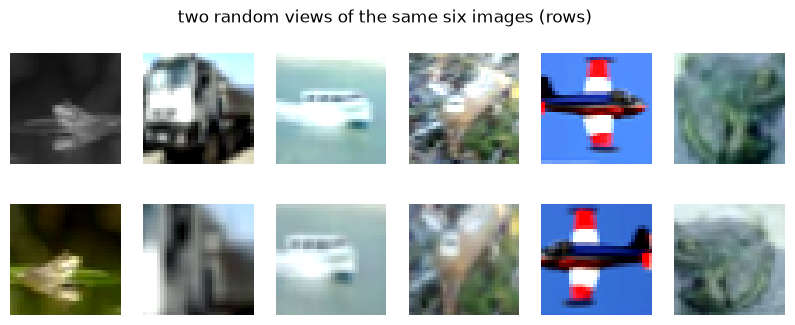

In [4]:
cifar = load_dataset(CIFAR_NAME)


def to_tensor(split: str) -> tuple[torch.Tensor, torch.Tensor]:
    """uint8 PIL images -> float (N, 3, 32, 32) in [0, 1] on DEVICE, labels (N,)."""
    images = np.stack([np.array(im) for im in cifar[split]["img"]])
    x = torch.from_numpy(images).permute(0, 3, 1, 2).contiguous().float().div(255)
    x = x.to(DEVICE)
    return x, torch.tensor(cifar[split]["label"])


train_x, train_y = to_tensor("train")
test_x, test_y = to_tensor("test")
# demo-sized: 15k images for SimCLR, 10k labelled memory + 2k queries for k-NN
ssl_x = train_x[:15000]
train_x, train_y = train_x[15000:25000], train_y[15000:25000]
test_x, test_y = test_x[:2000], test_y[:2000]
print(
    f"SimCLR images {tuple(ssl_x.shape)} | k-NN memory {len(train_x)} | queries "
    f"{len(test_x)}"
)
MEAN = torch.tensor([0.491, 0.482, 0.447], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.247, 0.243, 0.262], device=DEVICE).view(1, 3, 1, 1)


def augment(x: torch.Tensor) -> torch.Tensor:
    """Random resized crop, flip, colour jitter, greyscale. (B, 3, 32, 32) in [0, 1]."""
    b = len(x)
    # crop area in [0.2, 1] of the image, aspect ratio in [3/4, 4/3]
    area = torch.empty(b, device=x.device).uniform_(0.2, 1.0) * 32 * 32
    ratio = torch.exp(
        torch.empty(b, device=x.device).uniform_(math.log(3 / 4), math.log(4 / 3))
    )
    w = (area * ratio).sqrt().clamp(max=32)
    h = (area / ratio).sqrt().clamp(max=32)
    x0 = torch.rand(b, device=x.device) * (32 - w)
    y0 = torch.rand(b, device=x.device) * (32 - h)
    boxes = torch.stack(
        [torch.arange(b, device=x.device).float(), x0, y0, x0 + w, y0 + h], 1
    )
    x = roi_align(x, boxes, output_size=32, aligned=True)
    flip = torch.rand(b, device=x.device) < 0.5
    x = torch.where(flip.view(b, 1, 1, 1), x.flip(-1), x)
    jitter = torch.rand(b, device=x.device) < 0.8
    factors = torch.empty(b, 3, device=x.device).uniform_(0.6, 1.4)
    factors[~jitter] = 1.0
    gray = x.mul(
        torch.tensor([0.299, 0.587, 0.114], device=x.device).view(1, 3, 1, 1)
    ).sum(1, keepdim=True)
    x = x * factors[:, 0].view(b, 1, 1, 1)
    x = (x - x.mean((1, 2, 3), keepdim=True)) * factors[:, 1].view(b, 1, 1, 1) + x.mean(
        (1, 2, 3), keepdim=True
    )
    x = gray + (x - gray) * factors[:, 2].view(b, 1, 1, 1)
    to_gray = (torch.rand(b, device=x.device) < 0.2).view(b, 1, 1, 1)
    x = torch.where(to_gray, x.mean(1, keepdim=True).expand_as(x), x)
    return (x.clamp(0, 1) - MEAN) / STD


views = torch.cat([augment(train_x[:6]), augment(train_x[:6])])
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for ax, img in zip(axes.flat, views):
    ax.imshow((img * STD[0] + MEAN[0]).clamp(0, 1).permute(1, 2, 0).cpu())
    ax.axis("off")
plt.suptitle("two random views of the same six images (rows)")
plt.show()

In [5]:
def make_encoder() -> nn.Module:
    """CIFAR ResNet-18 (3x3 stem, no max-pool): (B, 3, 32, 32) -> (B, 512)."""
    net = torchvision.models.resnet18(num_classes=10)
    net.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
    net.maxpool = nn.Identity()
    net.fc = nn.Identity()
    return net


@torch.no_grad()
def knn_accuracy(encoder: nn.Module, k: int = 20) -> float:
    """Cosine k-NN (majority vote) on frozen features: labelled memory vs test queries."""
    encoder.eval()
    feats = [
        torch.cat(
            [
                F.normalize(encoder((x[s : s + 1000] - MEAN) / STD), dim=1)
                for s in range(0, len(x), 1000)
            ]
        )
        for x in (train_x, test_x)
    ]
    memory_y = train_y.to(DEVICE)
    votes = []
    for s in range(0, len(feats[1]), 1000):
        top = (feats[1][s : s + 1000] @ feats[0].T).topk(k, dim=1).indices
        votes.append(F.one_hot(memory_y[top], 10).sum(1).argmax(1).cpu())
    return (torch.cat(votes) == test_y).float().mean().item()


torch.manual_seed(SEED)
encoder = make_encoder().to(DEVICE)
head = nn.Sequential(
    nn.Linear(512, 512), nn.ReLU(inplace=True), nn.Linear(512, 128)
).to(DEVICE)
print(f"encoder {sum(p.numel() for p in encoder.parameters()) / 1e6:.1f} M params")
print(f"k-NN accuracy of the random encoder: {knn_accuracy(encoder):.3f}")

encoder 11.2 M params


k-NN accuracy of the random encoder: 0.368


SimCLR sees 15,000 unlabelled training images; the probe uses 10,000 other labelled training images as
memory and 2,000 test images as queries. Batch 256 (510 negatives per view), $\tau = 0.2$, AdamW
with a cosine schedule. The published
recipe trains for 800 epochs at batch 4,096 with LARS and reaches about 93% linear-probe accuracy
on CIFAR-10; a few epochs are enough to see the representation move.

In [6]:
EPOCHS, BATCH_NUM, TAU = 4, 256, 0.2
params = list(encoder.parameters()) + list(head.parameters())
opt = torch.optim.AdamW(params, lr=2e-3, weight_decay=1e-4)
steps = EPOCHS * (len(ssl_x) // BATCH_NUM)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=steps, pct_start=0.1)
history, knn_history = [], [knn_accuracy(encoder)]
start = time.time()


def train_epoch() -> None:
    """One SimCLR epoch over ssl_x, then the k-NN probe."""
    encoder.train()
    order = torch.randperm(len(ssl_x), device=DEVICE)
    for s in range(0, len(order) - BATCH_NUM + 1, BATCH_NUM):
        x = ssl_x[order[s : s + BATCH_NUM]]
        z1 = F.normalize(head(encoder(augment(x))), dim=1)
        z2 = F.normalize(head(encoder(augment(x))), dim=1)
        loss = nt_xent(z1, z2, TAU)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        history.append(loss.item())
    knn_history.append(knn_accuracy(encoder))
    print(
        f"epoch {len(knn_history) - 1}  NT-Xent {np.mean(history[-50:]):.3f}  k-NN "
        f"acc {knn_history[-1]:.3f}  ({time.time() - start:.0f} s)"
    )


for _ in range(EPOCHS // 2):
    train_epoch()

epoch 1  NT-Xent 4.899  k-NN acc 0.394  (93 s)


epoch 2  NT-Xent 4.093  k-NN acc 0.423  (219 s)


epoch 3  NT-Xent 3.752  k-NN acc 0.428  (345 s)


epoch 4  NT-Xent 3.593  k-NN acc 0.435  (479 s)


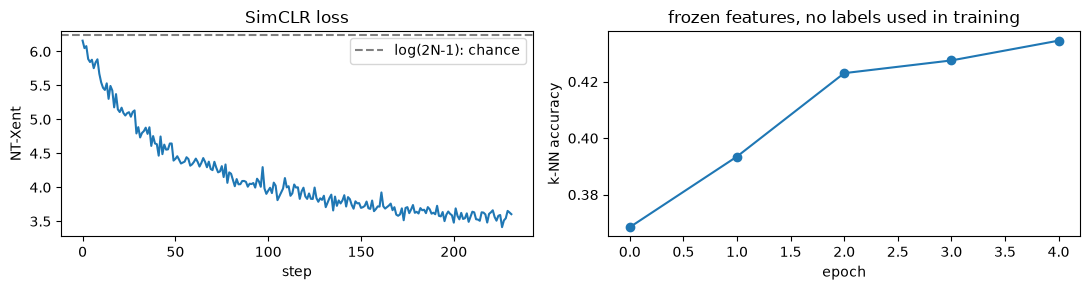

In [7]:
for _ in range(EPOCHS - EPOCHS // 2):
    train_epoch()

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(history)
axes[0].axhline(
    math.log(2 * BATCH_NUM - 1), color="grey", ls="--", label="log(2N-1): chance"
)
axes[0].set(xlabel="step", ylabel="NT-Xent", title="SimCLR loss")
axes[0].legend()
axes[1].plot(range(EPOCHS + 1), knn_history, marker="o")
axes[1].set(
    xlabel="epoch",
    ylabel="k-NN accuracy",
    title="frozen features, no labels used in training",
)
plt.tight_layout()
plt.show()

# 3) Image–Text Contrast: CLIP and SigLIP 2

The same objective with a caption as the positive gives a joint embedding space where text can
query images (retrieval) or name them (zero-shot classification). Both released models are run
on 512 Flickr8k test photos, each with its first human caption. The from-scratch losses must
reproduce the loss each library computes with `return_loss=True`.

In [8]:
flickr = load_dataset(PAIRS_NAME, split="test").select(range(512))
images = [im.convert("RGB") for im in flickr["image"]]
captions = flickr["caption_0"]
models = {}
for name in (CLIP_NAME, SIGLIP_NAME):
    model = AutoModel.from_pretrained(name).to(DEVICE).eval()
    processor = AutoProcessor.from_pretrained(name)
    models[name] = (model, processor)
    print(f"{name}: {sum(p.numel() for p in model.parameters()) / 1e6:.0f} M params")


@torch.no_grad()
def embed_pairs(name: str) -> tuple[torch.Tensor, torch.Tensor]:
    """Unit image and text embeddings (512, D) for the Flickr8k slice."""
    model, processor = models[name]
    padding = "max_length" if "siglip" in name else True
    u, v = [], []
    for s in range(0, len(images), 64):
        batch = processor(
            images=images[s : s + 64],
            text=captions[s : s + 64],
            padding=padding,
            truncation=True,
            max_length=64,
            return_tensors="pt",
        ).to(DEVICE)
        out = model(**batch)
        u.append(F.normalize(out.image_embeds, dim=-1))
        v.append(F.normalize(out.text_embeds, dim=-1))
    return torch.cat(u), torch.cat(v)


embeds = {name: embed_pairs(name) for name in models}
clip_model, clip_proc = models[CLIP_NAME]
sig_model, sig_proc = models[SIGLIP_NAME]
with torch.no_grad():
    b = clip_proc(
        images=images[:32], text=captions[:32], padding=True, return_tensors="pt"
    ).to(DEVICE)
    ref = clip_model(**b, return_loss=True).loss
    ours = clip_loss(*[e[:32] for e in embeds[CLIP_NAME]], clip_model.logit_scale.exp())
    print(
        f"CLIP   N=32: ours {ours:.4f} | transformers {ref:.4f} | scale t = "
        f"{clip_model.logit_scale.exp():.1f}"
    )
    b = sig_proc(
        images=images[:32],
        text=captions[:32],
        padding="max_length",
        max_length=64,
        truncation=True,
        return_tensors="pt",
    ).to(DEVICE)
    ref = sig_model(**b, return_loss=True).loss
    ours = siglip_loss(
        *[e[:32] for e in embeds[SIGLIP_NAME]],
        sig_model.logit_scale.exp(),
        sig_model.logit_bias,
    )
    print(
        f"SigLIP N=32: ours {ours:.4f} | transformers {ref:.4f} | t = "
        f"{sig_model.logit_scale.exp().item():.1f}, b = "
        f"{sig_model.logit_bias.item():.1f}"
    )

openai/clip-vit-base-patch32: 151 M params


google/siglip2-base-patch16-224: 375 M params


CLIP   N=32: ours 0.3410 | transformers 0.3410 | scale t = 100.0


SigLIP N=32: ours 1.4894 | transformers 1.4894 | t = 112.7, b = -16.8


## 3.1 Retrieval, and what the batch does to each loss

Recall@1 for image→text and text→image over all 512 pairs measures the shared space directly.
Then each loss is evaluated on random sub-batches of growing size $N$ with the *same* trained
weights. The InfoNCE value climbs with $N$ because every extra item is another competitor in
the softmax. The sigmoid loss has no softmax over the batch: each image's loss is a sum of
independent pair terms, so adding items only adds their own (small) negative terms and the value
moves much less.

In [9]:
print(f"{'model':<34} {'img->txt R@1':>12} {'txt->img R@1':>12}")
for name, (u, v) in embeds.items():
    sim = u @ v.T
    target = torch.arange(len(u), device=DEVICE)
    i2t = (sim.argmax(1) == target).float().mean().item()
    t2i = (sim.argmax(0) == target).float().mean().item()
    print(f"{name:<34} {i2t:12.3f} {t2i:12.3f}")

sizes = [8, 32, 128, 512]
curves = {"CLIP (InfoNCE)": [], "SigLIP 2 (sigmoid)": []}
generator = torch.Generator().manual_seed(SEED)
with torch.no_grad():
    for n in sizes:
        idx = [torch.randperm(512, generator=generator)[:n] for _ in range(8)]
        u, v = embeds[CLIP_NAME]
        curves["CLIP (InfoNCE)"].append(
            np.mean(
                [
                    clip_loss(u[i], v[i], clip_model.logit_scale.exp()).item()
                    for i in idx
                ]
            )
        )
        u, v = embeds[SIGLIP_NAME]
        curves["SigLIP 2 (sigmoid)"].append(
            np.mean(
                [
                    siglip_loss(
                        u[i], v[i], sig_model.logit_scale.exp(), sig_model.logit_bias
                    ).item()
                    for i in idx
                ]
            )
        )
for name, values in curves.items():
    print(f"{name:<20} " + "  ".join(f"N={n}: {l:.3f}" for n, l in zip(sizes, values)))

model                              img->txt R@1 txt->img R@1
openai/clip-vit-base-patch32              0.635        0.605
google/siglip2-base-patch16-224           0.799        0.803


CLIP (InfoNCE)       N=8: 0.067  N=32: 0.245  N=128: 0.605  N=512: 1.361
SigLIP 2 (sigmoid)   N=8: 1.211  N=32: 0.853  N=128: 1.016  N=512: 1.830


## 3.2 Probabilities, not rankings

A CLIP score is only meaningful relative to the other candidates in the softmax. A SigLIP score
is a calibrated per-pair probability $\sigma(t\,u^\top v + b)$, so it can say "none of these
captions fits" and supports multi-label tagging with a fixed threshold. The heat maps show both
models on 8 photos against their 8 captions.

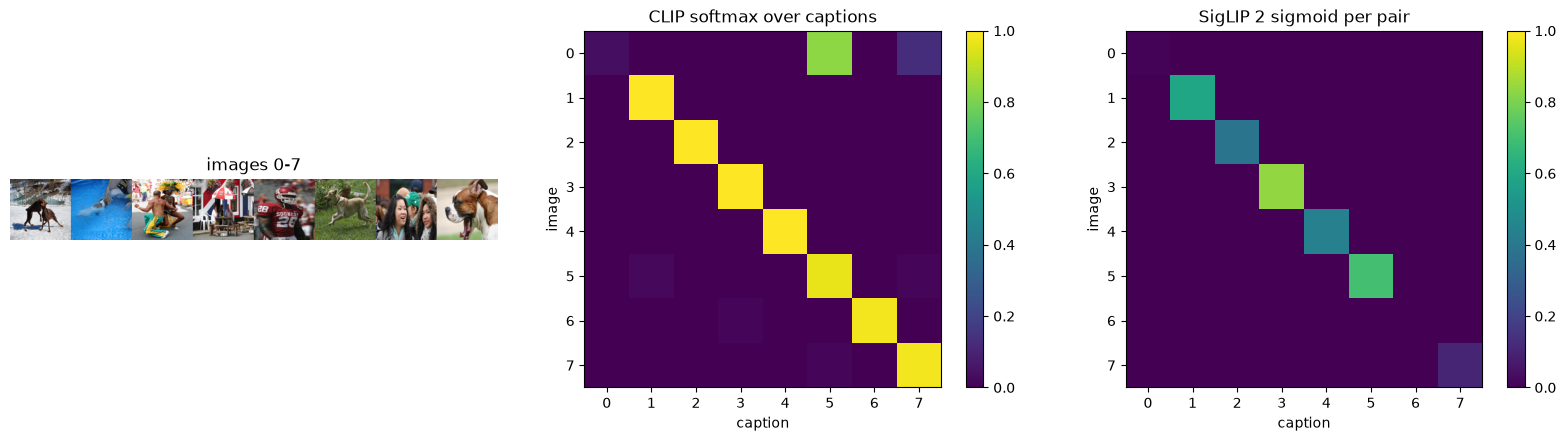

0: The dogs are in the snow in front of a fence .
1: a brown and white dog swimming towards some in the pool
2: A man and a woman in festive costumes dancing .


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (title, name) in zip(
    axes[1:],
    [
        ("CLIP softmax over captions", CLIP_NAME),
        ("SigLIP 2 sigmoid per pair", SIGLIP_NAME),
    ],
):
    u, v = embeds[name]
    with torch.no_grad():
        if name == CLIP_NAME:
            probs = (clip_model.logit_scale.exp() * u[:8] @ v[:8].T).softmax(dim=1)
        else:
            probs = torch.sigmoid(
                sig_model.logit_scale.exp() * u[:8] @ v[:8].T + sig_model.logit_bias
            )
    im = ax.imshow(probs.cpu(), vmin=0, vmax=1, cmap="viridis")
    ax.set(title=title, xlabel="caption", ylabel="image")
    plt.colorbar(im, ax=ax)
strip = np.concatenate([np.array(im.resize((96, 96))) for im in images[:8]], axis=1)
axes[0].imshow(strip)
axes[0].set_title("images 0-7")
axes[0].axis("off")
plt.tight_layout()
plt.show()
for i in range(3):
    print(f"{i}: {captions[i]}")

# 4) Practical Notes

- **Batch size and temperature.** InfoNCE needs many negatives; MoCo's queue and the momentum
  encoder exist to get them without a huge batch. A learned temperature (CLIP clamps
  $t \le 100$) usually settles near $\tau \approx 0.01$ for image–text and 0.1–0.5 for SimCLR.
- **Distributed training.** CLIP all-gathers embeddings so every device sees the global
  $N \times N$ matrix; SigLIP can instead pass text chunks around a ring and never materialise
  it, which made batch 32k on a few TPU hosts practical.
- **What changed after SimCLR.** Self-distillation methods (BYOL, DINO, DINOv2/v3) dropped
  explicit negatives and now give the strongest pure-vision features; contrastive image–text
  training (SigLIP 2, PE-Core, MetaCLIP 2) remains the standard way to get language-aligned
  encoders for VLMs.
- **Data beats loss.** Caption quality and filtering (DataComp, MetaCLIP curation, re-captioning)
  move zero-shot accuracy more than the choice between softmax and sigmoid.
- **SigLIP 2** adds captioning and self-distillation losses on top of the sigmoid loss and a
  NaFlex variant that keeps native aspect ratios.

# 5) Conclusion

| Objective | Positive | Batch coupling | Checked against |
|---|---|---|---|
| NT-Xent | other view of the same image | softmax over $2N - 1$ views | explicit loop; k-NN accuracy rises from a random-init baseline |
| CLIP InfoNCE | paired caption | softmax over $N$, both directions | `CLIPModel(return_loss=True)` |
| SigLIP sigmoid | paired caption | none: $N^2$ independent binary terms | `SiglipModel(return_loss=True)` |

- The augmentations define what a self-supervised contrastive model learns to ignore.
- InfoNCE grew about 20× from $N = 8$ to $N = 512$ on the same weights (0.07 to 1.36); the
  sigmoid loss moved far less (1.2 to 1.8), which is the practical reason SigLIP scales without
  huge synchronised batches.